# Bike-share evidence review: an integrated industry synthesis
**AI Foundations (Edward Hickman) · Udacity · Project 7**

**Industry:** urban bike-share operations / sustainable transportation.
**Problem:** before using a demand model in planning discussions, an analyst
needs data checks, an honest baseline comparison and interpretable evidence of
where errors are large. This prototype supplies that review evidence, not a
production forecasting service or bike-allocation system.

Project 2 statistical reasoning → new error diagnostics; Project 3 fixed
random-forest recipe → rental estimates; Project 6 bounded agentic patterns →
control over whether the other components run. `PRIOR_PROJECT_MAP.md` identifies
the actual prior artifacts and their immutable commits. `INTEGRATION_PLAN.md`
records choices and cases before execution.

AI assistance was used for coding, tests and drafting. Edward must understand,
review and personalize this synthesis under course policy. No classroom
submission, presentation or mentor defense is performed here.

## 1. The integration is functional, not a collection of old notebooks
The new orchestrator sends the original CSV through a dataset-specific quality
gate. Only an accepted table proceeds to date splitting and model fitting.
Actual model predictions then become inputs to new daily/hourly error diagnostics.
Every termination routes to a human, never an automatic dispatch action.

The model recipe and benchmark are intentionally reused from Project 3:
reproducing its metrics verifies wiring but is **not independent validation**.
Project 2 contributes methods and interpretation, not its student records or
school-study effect size. Project 6 contributes patterns, not its penguin data.
No neural network, generator, LLM or new framework is added without a role.

In [1]:
from pathlib import Path
import hashlib
import inspect
import json
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Code, display
import integrated_system
from integrated_system import CONFIG, FEATURES, ROOT, evaluate

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "pandas": pd.__version__, "scipy": scipy.__version__,
            "scikit_learn": sklearn.__version__}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(versions)
raw = pd.read_csv("data/hour.csv")
display(raw.head())
print("Shape:", raw.shape)
print("Original SHA-256:", hashlib.sha256(Path("data/hour.csv").read_bytes()).hexdigest())
display(CONFIG)

{'python': '3.11.18',
 'numpy': '2.4.6',
 'pandas': '3.1.1',
 'scipy': '1.17.1',
 'scikit_learn': '1.9.1'}

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Shape: (17379, 17)
Original SHA-256: e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f


{'dataset_id': 'bike_hourly_2011_2012',
 'relative_path': 'data/hour.csv',
 'source_sha256': 'e03de4ee4ef4dc376ac6e04bf829673c6269e8eba5c60fa121640fa2f829504f',
 'max_bytes': 2000000,
 'max_rows': 20000,
 'max_tool_calls': 5,
 'categorical': ['season',
  'yr',
  'mnth',
  'hr',
  'holiday',
  'weekday',
  'workingday',
  'weathersit'],
 'numeric': ['temp', 'atemp', 'hum', 'windspeed'],
 'allowed_categories': {'season': [1, 2, 3, 4],
  'yr': [0, 1],
  'mnth': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
  'hr': [0,
   1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23],
  'holiday': [0, 1],
  'weekday': [0, 1, 2, 3, 4, 5, 6],
  'workingday': [0, 1],
  'weathersit': [1, 2, 3, 4]},
 'seed': 20261119,
 'forest': {'n_estimators': 150,
  'max_depth': 14,
  'min_samples_leaf': 2,
  'max_features': 1.0,
  'bootstrap': True,
  'criterion': 'squared_error',
  'n_jobs': 1}}

## 2. Architecture, interfaces and responsibilities
One rule-based controller has five tool names and a five-call ceiling.
Each request gets a fresh state; it holds observations, completed tools,
counter and trace, plus temporary data, split, predictions and diagnostic frames.
The agent is not an LLM or a general planner.

`load` returns the registered table; `quality` returns aggregate findings;
`split` creates whole-date partitions; `model` fits development data and returns
test predictions and scores; `diagnose` consumes those predictions, not a
separate unrelated dataset. Quality findings hold the run before splitting;
failure/budget exhaustion stops without inferring approval.
The harness writes evaluation artifacts; the tools do not edit input data.

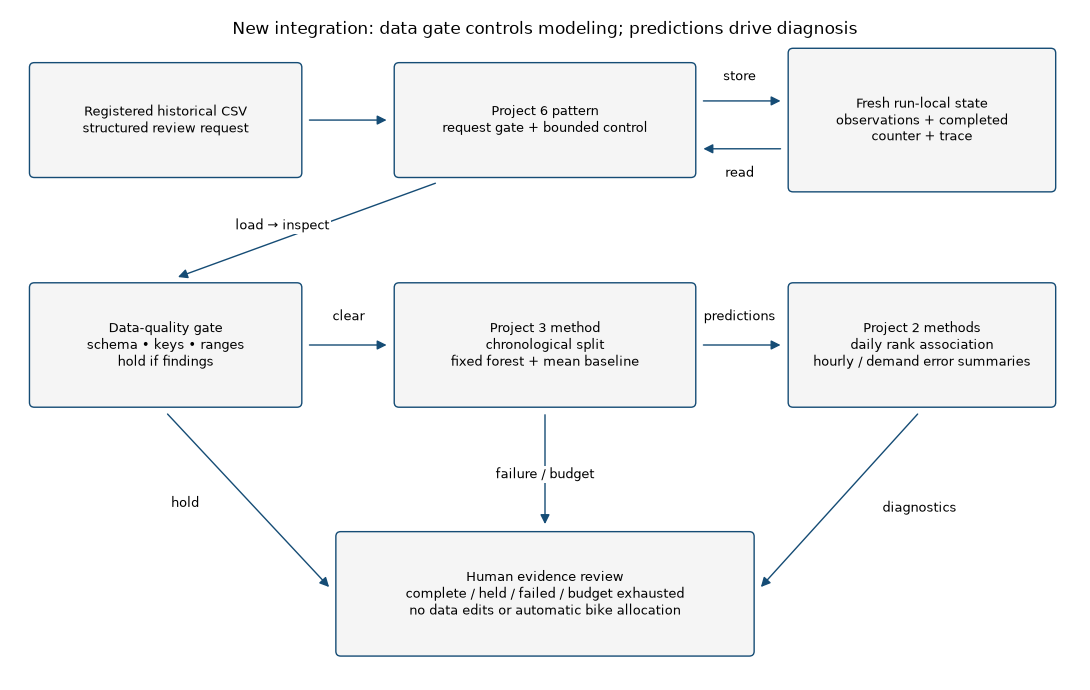

In [2]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.set(xlim=(0, 11), ylim=(0, 7))
ax.axis("off")
boxes = [
    (0.25, 5.3, 2.7, 1.1, "Registered historical CSV\nstructured review request"),
    (4.0, 5.3, 3.0, 1.1, "Project 6 pattern\nrequest gate + bounded control"),
    (8.05, 5.15, 2.65, 1.4, "Fresh run-local state\nobservations + completed\ncounter + trace"),
    (0.25, 2.9, 2.7, 1.2, "Data-quality gate\nschema • keys • ranges\nhold if findings"),
    (4.0, 2.9, 3.0, 1.2, "Project 3 method\nchronological split\nfixed forest + mean baseline"),
    (8.05, 2.9, 2.65, 1.2, "Project 2 methods\ndaily rank association\nhourly / demand error summaries"),
    (3.4, 0.3, 4.2, 1.2, "Human evidence review\ncomplete / held / failed / budget exhausted\nno data edits or automatic bike allocation"),
]
for x, y, w, h, text in boxes:
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                               edgecolor="#154C75", facecolor="#F5F5F5"))
    ax.text(x+w/2, y+h/2, text, ha="center", va="center", fontsize=9.5)

def arrow(start, end, text="", position=None):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, color="#154C75"))
    if position:
        ax.text(*position, text, ha="center", va="center", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})

arrow((3.05, 5.85), (3.9, 5.85))
arrow((7.1, 6.05), (7.95, 6.05), "store", (7.5, 6.3))
arrow((7.95, 5.55), (7.1, 5.55), "read", (7.5, 5.3))
arrow((4.4, 5.2), (1.7, 4.2), "load → inspect", (2.8, 4.75))
arrow((3.05, 3.5), (3.9, 3.5), "clear", (3.48, 3.8))
arrow((7.1, 3.5), (7.95, 3.5), "predictions", (7.5, 3.8))
arrow((1.6, 2.8), (3.3, 0.95), "hold", (1.8, 1.85))
arrow((9.35, 2.8), (7.7, 0.95), "diagnostics", (9.35, 1.8))
arrow((5.5, 2.8), (5.5, 1.6), "failure / budget", (5.5, 2.15))
ax.text(5.5, 6.75, "New integration: data gate controls modeling; predictions drive diagnosis",
        ha="center", fontsize=12)
fig.tight_layout()
fig.savefig(OUT / "architecture_diagram.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 3. Complete executable implementation
The following is the actual `integrated_system.py` module used below.
Its fixed features exclude target-derived counts and identifiers.
The forest recipe follows the prior capstone, grounded in the ensemble approach
of Breiman (2001). This integration does not claim to improve its predictive score.

In [3]:
display(Code(inspect.getsource(integrated_system), language="python"))

"""Offline bike-share evidence pipeline; no LLM, API, data repair or dispatch."""
from dataclasses import dataclass, field
import hashlib
import io
import json
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


ROOT = Path(__file__).resolve().parent
CONFIG = json.loads((ROOT / "config.json").read_text())
FEATURES = CONFIG["categorical"] + CONFIG["numeric"]
REQUIRED = FEATURES + ["instant", "dteday", "casual", "registered", "cnt"]


class ToolFailure(Exception):
    pass


@dataclass(frozen=True)
class Request:
    dataset_id: str = "bike_hourly_2011_2012"
    intent: str = "retrospective_review"
    max_tool_calls: int = 5


@dataclass
class State:
    completed: list = field(default_factory=list)
    observations: dict = field(default_factory=dict)
    trace: list = field(default_factory=list)
    calls: int = 0
    frame: pd.DataFrame | None = None
    development: pd.DataFrame | None = None
    test: pd.DataFrame | None = None
    predictions: pd.DataFrame | None = None
    daily: pd.DataFrame | None = None
    hourly: pd.DataFrame | None = None

    def log(self, action, reason, outcome):
        self.trace.append({"sequence": len(self.trace) + 1, "action": action,
                           "reason": reason, "outcome": outcome})


class EvidenceTools:
    def __init__(self, fixture=None, fail_tool=None):
        self.fixture = fixture
        self.fail_tool = fail_tool

    def dispatch(self, name, state):
        tools = {"load": self.load, "quality": self.quality, "split": self.split,
                 "model": self.model, "diagnose": self.diagnose}
        if name not in tools or name == self.fail_tool:
            raise ToolFailure("Unknown or deliberately failed evaluation tool")
        return tools[name](state)

    def load(self, state):
        if self.fixture is None:
            path = ROOT / CONFIG["relative_path"]
            if path.stat().st_size > CONFIG["max_bytes"]:
                raise ToolFailure("Registered source exceeds byte limit")
            raw = path.read_bytes()
            if hashlib.sha256(raw).hexdigest() != CONFIG["source_sha256"]:
                raise ToolFailure("Registered source fingerprint mismatch")
            frame = pd.read_csv(io.BytesIO(raw))
        else:
            frame = self.fixture.copy(deep=True)
        if not 0 < len(frame) <= CONFIG["max_rows"] or not 0 < len(frame.columns) <= 20:
            raise ToolFailure("Invalid input dimensions")
        if not frame.columns.is_unique:
            raise ToolFailure("Repeated column names")
        state.frame = frame
        return {"rows": len(frame), "columns": len(frame.columns),
                "source": "declared test fixture" if self.fixture is not None else "pinned historical CSV"}

    def quality(self, state):
        frame = state.frame
        missing = sorted(set(REQUIRED) - set(frame.columns))
        extra = len(set(frame.columns) - set(REQUIRED))
        issues = []
        if missing:
            issues.append("required_columns_missing")
        if extra:
            issues.append("unrecognized_columns")
        if missing or extra:
            return {"issues": issues, "missing_columns": missing, "extra_columns": extra}
        if frame.isna().any().any():
            issues.append("missing_values")
        if frame.duplicated(["dteday", "hr"]).any():
            issues.append("duplicate_timestamp")
        numeric = frame.drop(columns="dteday").apply(pd.to_numeric, errors="coerce")
        if not np.isfinite(numeric.to_numpy(dtype=float)).all():
            issues.append("nonnumeric_or_nonfinite")
        categories = [c for c, allowed in CONFIG["allowed_cat

## 4. Execute the integrated system and designed gate/failure cases
The original data come from real 2011–2012 Capital Bikeshare logs distributed
by UCI (Fanaee-T, 2013; Fanaee-T & Gama, 2014). The released file has 17,379
records, despite a different landing-page count. In-memory fixtures deliberately
alter copies to exercise gates; these are not alleged defects in the field data.
The agent accepts only a registered historical review request, not arbitrary paths.

In [4]:
result, scenarios = evaluate(OUT)
display(result["observations"])
display(pd.DataFrame(result["trace"]))
display(scenarios)
assert result["status"] == "completed"
assert result["completed_tools"] == ["load", "quality", "split", "model", "diagnose"]

{'load': {'rows': 17379, 'columns': 17, 'source': 'pinned historical CSV'},
 'quality': {'issues': [],
  'missing_cells': 0,
  'duplicate_keys': 0,
  'invalid_category_columns': [],
  'scope': 'Configured structural/range checks; no quality certification or automatic cleaning.'},
 'split': {'development_rows': 13891,
  'test_rows': 3488,
  'development_end': '2012-08-06 23:00:00',
  'test_start': '2012-08-07 00:00:00',
  'test_end': '2012-12-31 23:00:00',
  'test_dates': 147,
  'unrecorded_clock_hours': 165},
 'model': {'forest': {'mae': 72.57380438490063,
   'rmse': 104.6460517699244,
   'r2': 0.7747540151743194},
  'baseline': {'mae': 174.97113521542894,
   'rmse': 232.55875344587955,
   'r2': -0.11244038117651556},
  'train_demand_q75': 258.0,
  'features': ['season',
   'yr',
   'mnth',
   'hr',
   'holiday',
   'weekday',
   'workingday',
   'weathersit',
   'temp',
   'atemp',
   'hum',
   'windspeed'],
  'note': 'Reuses Project 3 fixed recipe and previously seen benchmark; not i

,sequence,action,reason,outcome
0,1,load,Load the registered read-only source.,requested
1,2,load,Aggregate observation stored in fresh run-loca...,observed
2,3,quality,"Observe required schema, completeness, keys an...",requested
3,4,quality,Aggregate observation stored in fresh run-loca...,observed
4,5,split,Quality gate has no configured findings; isola...,requested
5,6,split,Aggregate observation stored in fresh run-loca...,observed
6,7,model,Fit fixed Project 3 recipe on development only...,requested
7,8,model,Aggregate observation stored in fresh run-loca...,observed
8,9,diagnose,Use model residuals for descriptive Project 2-...,requested
9,10,diagnose,Aggregate observation stored in fresh run-loca...,observed


,scenario,status,tool_calls,completed_stages
0,original,completed,5,"load,quality,split,model,diagnose"
1,missing_value,held,2,"load,quality"
2,duplicate_key,held,2,"load,quality"
3,invalid_hour,held,2,"load,quality"
4,unknown_weather,held,2,"load,quality"
5,nonfinite,held,2,"load,quality"
6,missing_column,held,2,"load,quality"
7,allocation_request,blocked,0,
8,low_budget,budget_exhausted,2,"load,quality"
9,model_failure,failed,4,"load,quality,split"


## 5. How integration changes behavior
Six flawed-input fixtures are held after load/quality, **before any fitting**.
The allocation request is blocked with zero calls. A two-call budget ends
incomplete even though data checks found no issue. An injected model failure
prevents the statistical diagnosis; it cannot silently reuse old predictions.
These observations show one component controlling the next, not merely
placing prior outputs beside one another.

In [5]:
for name in ["missing_value", "allocation_request", "low_budget", "model_failure"]:
    case = json.loads((OUT / f"{name}.json").read_text())
    print("\n", name, case["status"], case["reason"])
    display(pd.DataFrame(case["trace"]))


 missing_value held Quality findings block splitting, model fitting and diagnosis.


,sequence,action,reason,outcome
0,1,load,Load the registered read-only source.,requested
1,2,load,Aggregate observation stored in fresh run-loca...,observed
2,3,quality,"Observe required schema, completeness, keys an...",requested
3,4,quality,Aggregate observation stored in fresh run-loca...,observed
4,5,finish,"Quality findings block splitting, model fittin...",held



 allocation_request blocked Only registered historical review is permitted.


,sequence,action,reason,outcome
0,1,finish,Only registered historical review is permitted.,blocked



 low_budget budget_exhausted Next required tool would exceed the call budget.


,sequence,action,reason,outcome
0,1,load,Load the registered read-only source.,requested
1,2,load,Aggregate observation stored in fresh run-loca...,observed
2,3,quality,"Observe required schema, completeness, keys an...",requested
3,4,quality,Aggregate observation stored in fresh run-loca...,observed
4,5,finish,Next required tool would exceed the call budget.,budget_exhausted



 model_failure failed No retry and no approval inferred from partial evidence.


,sequence,action,reason,outcome
0,1,load,Load the registered read-only source.,requested
1,2,load,Aggregate observation stored in fresh run-loca...,observed
2,3,quality,"Observe required schema, completeness, keys an...",requested
3,4,quality,Aggregate observation stored in fresh run-loca...,observed
4,5,split,Quality gate has no configured findings; isola...,requested
5,6,split,Aggregate observation stored in fresh run-loca...,observed
6,7,model,Fit fixed Project 3 recipe on development only...,requested
7,8,model,Tool failed; remaining stages were not performed.,error
8,9,finish,No retry and no approval inferred from partial...,failed


## 6. Predictive performance and new statistical interpretation
The original benchmark has 13,891 earlier training rows and 3,488 later test
rows over 147 dates. No same-day overlap occurs. The twelve predictors include
contemporaneously observed weather: this is **retrospective conditional
estimation**, not an advance weather-based forecast. The 165 unrecorded clock
hours are not invented as zero demand.

The forest has RMSE 104.65 versus 232.56 rentals/hour for the training-mean
baseline; its mean absolute miss is 72.57 rentals/hour. This reproduces Project
3, rather than demonstrating a new accuracy improvement. The new diagnosis
asks where that performance might mislead an operations analyst.

In [6]:
p = pd.read_csv(OUT / "test_predictions.csv")
daily = pd.read_csv(OUT / "daily_diagnostics.csv")
hourly = pd.read_csv(OUT / "hourly_diagnostics.csv")
display(pd.DataFrame.from_dict({k: result["observations"]["model"][k]
                               for k in ["forest", "baseline"]}, orient="index"))
display(daily.head())
display(hourly)
display(result["observations"]["diagnose"])

,mae,rmse,r2
forest,72.573804,104.646052,0.774754
baseline,174.971135,232.558753,-0.112440


,date,n,mean_temp,mean_residual,mae
0,2012-08-07,24,0.735833,31.435051,50.998922
1,2012-08-08,24,0.750000,33.230524,54.182271
2,2012-08-09,24,0.755833,25.022559,35.295568
3,2012-08-10,24,0.715833,-21.865811,47.415134
4,2012-08-11,24,0.692500,29.092113,53.951933


,hr,n,mae,mean_residual
0,0,146,35.870526,-15.144277
1,1,145,26.075965,-3.753697
2,2,145,17.850742,-6.423694
3,3,142,11.044657,-7.632993
4,4,144,10.228714,-9.300696
5,5,145,13.346163,-4.888280
6,6,145,52.069506,-2.082851
7,7,145,113.016819,57.311467
8,8,145,101.866189,52.994694
9,9,145,79.646037,53.605120


{'daily_n': 147,
 'daily_temp_residual_rho': -0.07714684553943058,
 'inference': 'Descriptive only; serial dependence and season/year confounding; no p-value or causal claim.',
 'higher_demand': {'n': 1413,
  'mae': 123.8008102462809,
  'mean_residual': 119.73875733561039},
 'lower_demand': {'n': 2075, 'mae': 37.69006497182578},
 'group_definition': 'Actual test count >= development count 75th percentile; retrospective stress analysis, not a deployable routing rule.',
 'worst_hour_by_mae': 16,
 'recommendation': 'Human review only; no allocation, staffing, causal or fairness approval.'}

The development-only 75th-percentile rental count is **258**. Among the 1,413
test hours at or above that count, MAE is **123.80** and mean signed error is
**+119.74** rentals/hour (actual minus prediction). Among 2,075 other test hours,
MAE is **37.69**. This is a retrospective stress grouping using actual outcomes;
it is not a rule that can identify future demand groups before outcomes arrive.
The worst clock hour by MAE is 16:00; all 24 hourly groups are included above.

Following Project 2's rank-based reasoning, the new daily mean temperature /
mean signed residual Spearman coefficient is **−0.0771** across **147 dates**.
It is a weak descriptive monotonic association, not a temperature effect or
evidence that all weather errors are absent. SciPy defines the coefficient as
rank-based association (SciPy developers, n.d.). Serial dependence,
season/year confounding, aggregation and repeated use of the earlier benchmark
preclude treating this as a confirmatory independent-samples test. No
significance claim or p-value is reported, and no tuning follows this diagnostic.

## 7. Plain-language interpretation
The program checks a historical bike-rental table before building an estimate.
If a test copy contains missing information or a repeated date-and-hour record,
it stops and asks for a person to review it. On the original records, its
estimates miss by about 73 rentals per hour on average. During busier hours
the average miss is about 124 rentals, usually because the estimate is too low.
That makes the results useful for investigating weaknesses, not for deciding
how many bikes to move. The table records completed rentals, so it cannot tell
us how many people wanted a bike but could not get one.

## 8. Responsible use, boundaries and professional reflection
Observed rental counts reflect access as well as desire to travel. Automatically
rewarding high recorded use with more bikes could neglect areas with existing
service shortages. These aggregate records contain no station or demographic
evidence adequate to audit that risk. Hourly error groups are **not a fairness
audit**, and no emissions, ridership, cost or service-equity benefit was measured.

Implemented protections are fixed read-only tool names, request restrictions,
source fingerprint, bounded calls, data gates, explicit failure statuses and human
review; they are not NIST certification (NIST, 2023). Deployment would additionally
need current local/station data, weather forecasts with known availability,
service-equity review, timeouts/isolation, access controls and accountable
monitoring. No LLM, data-repair capability, persistent memory, dispatch tool,
causal inference or prediction intervals are implemented.

The important synthesis lesson is that a lower average error does not establish
operational suitability. A quality gate can prevent some bad computations, while
statistical diagnosis can expose the limits of apparently good model scores.
Edward should personalize this reflection and be ready to explain each design
choice; Project 8's presentation and mentor defense remain separate.

## References
Breiman, L. (2001). Random forests. *Machine Learning, 45*, 5–32.
https://doi.org/10.1023/A:1010933404324

Fanaee-T, H. (2013). *Bike Sharing* [Data set]. UCI Machine Learning Repository.
https://doi.org/10.24432/C5W894

Fanaee-T, H., & Gama, J. (2014). Event labeling combining ensemble detectors
and background knowledge. *Progress in Artificial Intelligence, 2*, 113–127.
https://doi.org/10.1007/s13748-013-0040-3

National Institute of Standards and Technology. (2023).
*Artificial intelligence risk management framework (AI RMF 1.0)* (NIST AI 100-1).
https://doi.org/10.6028/NIST.AI.100-1

SciPy developers. (n.d.). *scipy.stats.spearmanr*.
https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html

## Integrated artifact summary
This new bike-share review pipeline combines Project 6's bounded control,
Project 3's fixed demand model and Project 2's statistical interpretation.
Its quality gate controls whether fitting and diagnosis may run, and actual
model residuals drive the new diagnostic outputs.
The original data reproduce the prior benchmark while the new analysis exposes
larger underestimation during higher-demand hours.
Designed faulty inputs and blocked requests demonstrate limited safeguards,
not comprehensive security or production readiness.
The final evidence remains with a human and cannot justify automatic allocation,
causal conclusions or fairness claims.